# edaSol - usage example

In [1]:
# Setup: impor edaSol, seaborn, dan muat dataset titanic
%matplotlib inline
import seaborn as sns

from edaSol import (
    quick_summary,
    data_quality_report,
    detect_outliers_iqr,
    describe_categorical,
    detect_duplicates,
    plot_numerical_dist,
    plot_correlation_heatmap,
    plot_missing_matrix,
    plot_categorical_dist,
    plot_boxplots,
    plot_pairplot,
)

df = sns.load_dataset("titanic")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 1. quick_summary

Summary of each column: data type, number and percentage of nulls, number of unique values, and example values.

In [2]:
quick_summary(df)

,Data Type,Null Count,Null Percent,Unique Count,Sample Value
survived,int64,0,0.00,2,0
pclass,int64,0,0.00,3,3
sex,object,0,0.00,2,male
age,float64,177,19.87,88,22.0
sibsp,int64,0,0.00,7,1
parch,int64,0,0.00,7,0
fare,float64,0,0.00,248,7.25
embarked,object,2,0.22,3,S
class,category,0,0.00,3,Third
who,object,0,0.00,3,man


## 2. data_quality_report

Data quality reports in one dictionary. Here we print the summary and display the missing values ​​table.

In [3]:
report = data_quality_report(df)
print("Shape:", report["shape"])
print("Duplikat:", report["duplicates"])
print("Memori (MB):", report["memory_usage"])
report["missing"]

Shape: (891, 15)
Duplikat: 107
Memori (MB): 0.31


,Null Count,Null Percent,Non-Null Count
deck,688,77.22,203
age,177,19.87,714
embarked,2,0.22,889
embark_town,2,0.22,889


## 3. detect_outliers_iqr

Detect outliers in the numeric column `fare` using the IQR method, while taking the lower and upper limits.

In [4]:
outliers, lower, upper = detect_outliers_iqr(df, "fare", return_bounds=True)
print(f"Jumlah outlier fare: {len(outliers)}")
print(f"Batas bawah: {lower:.2f} | Batas atas: {upper:.2f}")

Jumlah outlier fare: 116
Batas bawah: -26.72 | Batas atas: 65.63


## 4. describe_categorical

Statistics for categorical columns: count, cardinality, highest value, frequency, and percentage.

In [5]:
describe_categorical(df)

,Count,Unique,Top Value,Top Frequency,Top Percent
Column,,,,,
sex,891,2,male,577,64.76
embarked,889,3,S,644,72.28
class,891,3,Third,491,55.11
who,891,3,man,537,60.27
deck,203,7,C,59,6.62
embark_town,889,3,Southampton,644,72.28
alive,891,2,no,549,61.62


## 5. detect_duplicates

Take duplicate rows. Titanic has many identical rows, so we'll just show a few.

In [6]:
detect_duplicates(df).head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
47,1,3,female,NaN,0,0,7.7500,Q,Third,woman,False,NaN,Queenstown,yes,True
76,0,3,male,NaN,0,0,7.8958,S,Third,man,True,NaN,Southampton,no,True
77,0,3,male,NaN,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
87,0,3,male,NaN,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
95,0,3,male,NaN,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 6. plot_numerical_dist

Histogram with KDE curve for selected numeric columns.

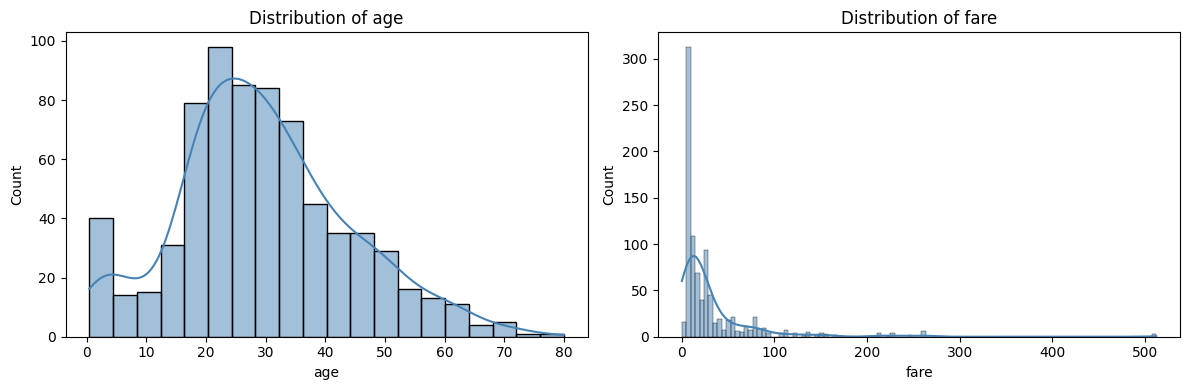

In [7]:
plot_numerical_dist(df, columns=["age", "fare"])

## 7. plot_correlation_heatmap

Heatmap of correlation between numeric columns.

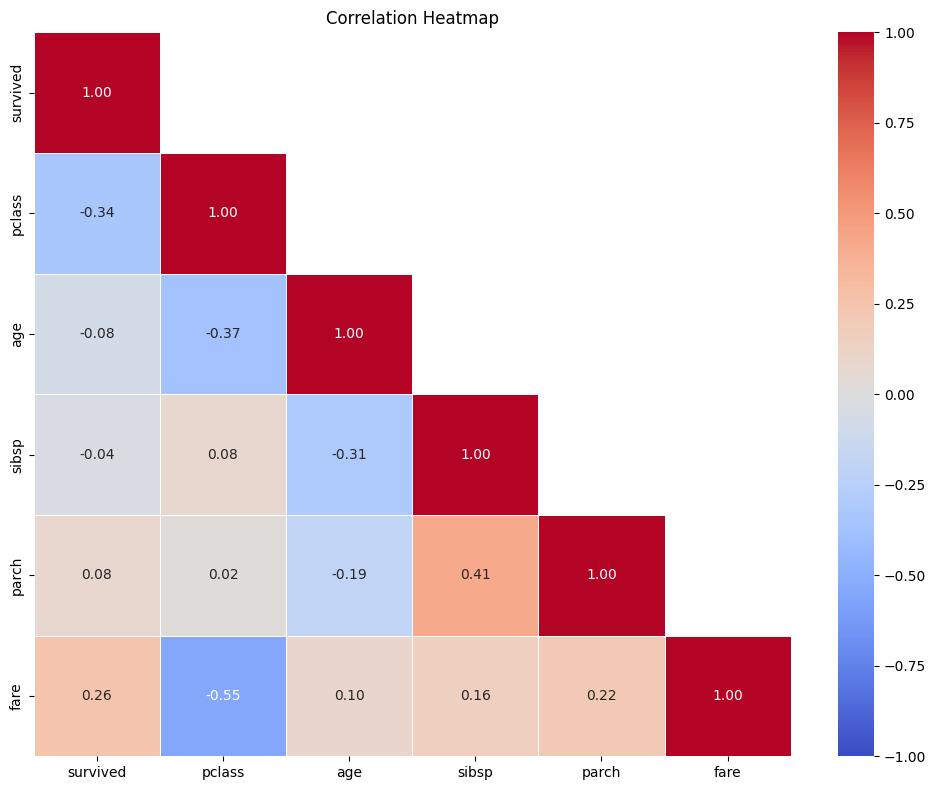

In [8]:
plot_correlation_heatmap(df)

## 8. plot_missing_matrix

Missing value patterns across the dataset as a matrix.

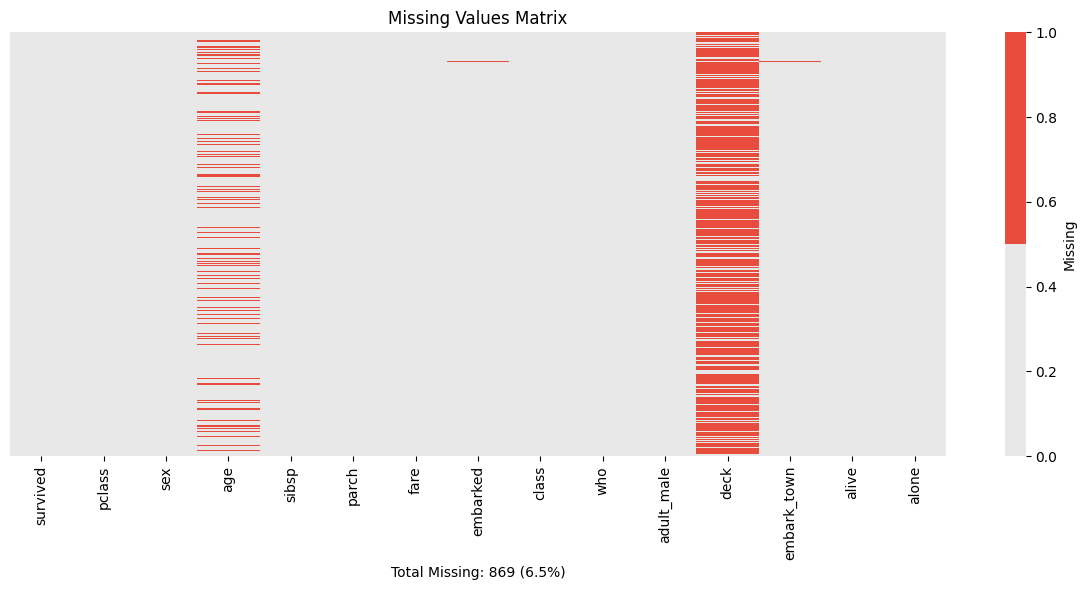

In [9]:
plot_missing_matrix(df)

## 9. plot_categorical_dist

Bar plot of the frequency of values ​​for the selected categorical column.

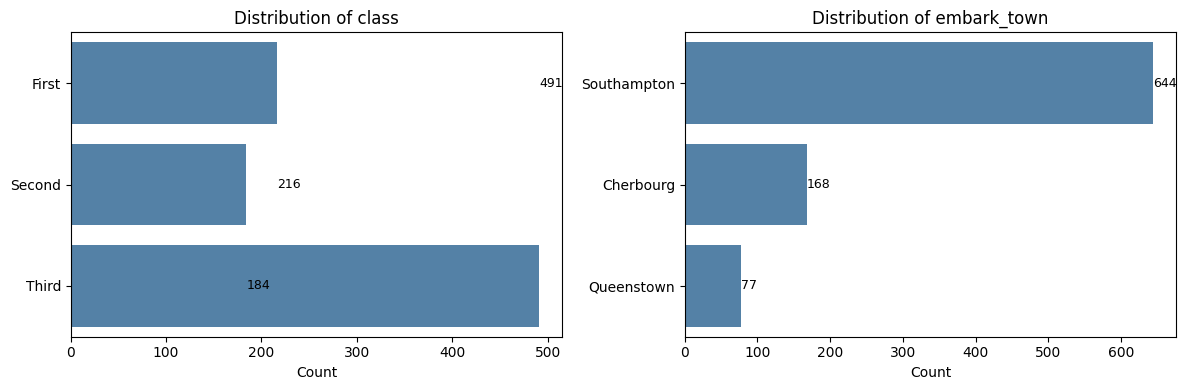

In [10]:
plot_categorical_dist(df, columns=["class", "embark_town"])

## 10. plot_boxplots

Boxplot to see the distribution and outliers of numeric columns.

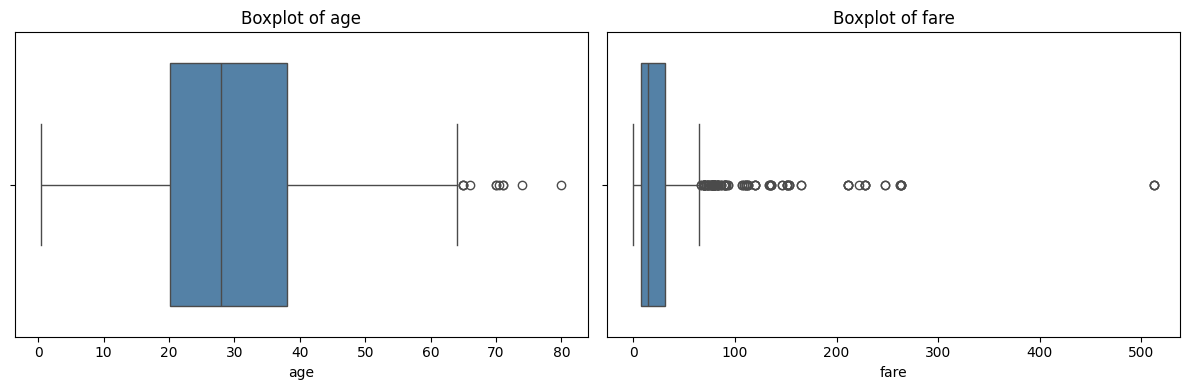

In [11]:
plot_boxplots(df, columns=["age", "fare"])